Dataset Shape: (1000, 16)

First 5 records:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2          Heavy               3            Yes       No     Yes   
3            NaN               4             No      Yes      No   
4            NaN               6             No      Yes      No   

   Stress Level  Blood Sugar Exercise Induced Angina   Chest Pain Type  \
0             8          119                     Yes   Atypical 

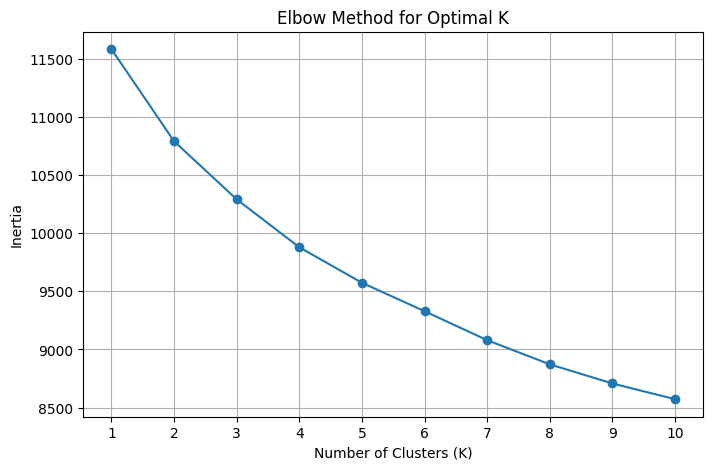


Selected Optimal K: 3

Clustered Dataset:
   Age  Gender  Cholesterol  Blood Pressure  Heart Rate  Smoking  \
0   75  Female          228             119          66  Current   
1   48    Male          204             165          62  Current   
2   53    Male          234              91          67    Never   
3   69  Female          192              90          72  Current   
4   62  Female          172             163          93    Never   
5   77    Male          309             110          73    Never   
6   64  Female          211             105          86   Former   
7   60  Female          208             148          83    Never   
8   37  Female          317             137          66  Current   
9   63    Male          204             141          68   Former   

  Alcohol Intake  Exercise Hours Family History Diabetes Obesity  \
0          Heavy               1             No       No     Yes   
1            NaN               5             No       No      No   
2   

In [1]:
# EXERCISE - 12 (K-MEANS CLUSTERING)

#!/usr/bin/env python
# coding: utf-8

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.cluster import KMeans

df = pd.read_csv("/content/heart_disease_dataset.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 records:")
print(df.head())

X = df.drop("Heart Disease", axis=1)

numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

categorical_features = X.select_dtypes(
    include=["object"]
).columns

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]

)

X_processed = preprocessor.fit_transform(X)

# Check whether X_processed is sparse or already a NumPy array
if hasattr(X_processed, "toarray"):
    X_processed = X_processed.toarray()

print("\nProcessed Data Shape:")
print(X_processed.shape)

# ------------------------------------------------------------
# Step 7: Apply Elbow Method
# ------------------------------------------------------------

inertia = []

K = range(1, 11)

for k in K:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_processed)

    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    K,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("Elbow Method for Optimal K")

plt.xticks(K)

plt.grid(True)

plt.show()

# Change this value after observing the elbow plot.
optimal_k = 3

print("\nSelected Optimal K:", optimal_k)

kmeans = KMeans(
    n_clusters=optimal_k,

    random_state=42,
    n_init=10
)

clusters = kmeans.fit_predict(X_processed)

df["Cluster"] = clusters

print("\nClustered Dataset:")
print(df.head(10))

print("\nNumber of records in each cluster:")
print(df["Cluster"].value_counts().sort_index())